# P2-f2 — Standardized innovation diagnostics (test 2024-01-01 → 2026-09-30)

Validation guide §5, Test 3. For each asset and model, Z_{t+1} = r_{t+1} / √h_{t+1} (zero-mean assumption).

| Check | What it asks | Computed here |
|---|---|---|
| A. Calibration | Is the forecast right on average? | mean Z, Var Z, **mean Z²** (≈ 1 if calibrated; same Z² term as in QLIKE), per-year mean Z² |
| B. Remaining clustering | Does the forecast track variance through time? | Ljung–Box on Z² and \|Z\| at lags 5 and 22; ACF of Z² for lags 1–22 vs raw r² |
| C. Distribution | Tails, skew, extreme shocks | skew, excess kurtosis, max \|Z\|, share \|Z\| > 3, QQ plot vs normal |

- Forecasts: `forecasts/<SYM>-<model>.csv`, annual walk-forward, `split == 'test'`. Naive = carry forward `yz_var_22` (the benchmark used in the model notebooks).
- Realized: signed next-day close-to-close return, 100 · `r` of the next bar (checked against `r2_next`).
- All models for an asset are evaluated on the same dates.
- Ljung–Box is run on the pooled test period only. One year (≈ 250–365 days) is too few for 22 lags to have useful power. Per-year stability is shown with mean Z² instead.
- Baseline for B: Ljung–Box / ACF of raw r² (what a constant-variance forecast would leave). The point is how much the model removes, not the p-value alone.
- Target still provisional.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf

YZ, FC = Path('yz_data'), Path('forecasts')
ASSETS = ['BTC', 'ETH', 'QQQ', 'XAUUSD']
MODELS = ['HAR-YZ', 'GARCH11', 'EGARCH11', 'GJRGARCH11']
TEST = (pd.Timestamp('2024-01-01', tz='UTC'), pd.Timestamp('2026-10-01', tz='UTC'))  # target dates [start, end)
LAGS = [5, 22]
SCALE = 1e4  # log-return variance -> %^2

COL = {'raw r²': '#b4b2ab', 'naive': '#eb6834', 'HAR-YZ': '#2a78d6', 'GARCH11': '#1baf7a',
       'EGARCH11': '#9b59b6', 'GJRGARCH11': '#c0392b'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
                     'lines.linewidth': 1.2, 'figure.dpi': 110})

In [2]:
def load(sym):
    d = pd.read_csv(YZ / f'{sym}-yz-1d.csv', index_col=0)
    d.index = pd.to_datetime(d.index, utc=True)
    d['r_next'] = 100 * d.r.shift(-1)          # signed next-day return, %
    d['naive'] = d.yz_var_22 * SCALE
    d['y'] = d.r2_next * SCALE
    return d

def build(sym):
    d = load(sym)
    h = {m: pd.read_csv(FC / f'{sym}-{m}.csv', index_col=0, parse_dates=['target_date']) for m in MODELS}
    for m, f in h.items():
        f.index = pd.to_datetime(f.index, utc=True)
        h[m] = f.loc[f.split == 'test', 'h']
    out = pd.DataFrame(h).join(d[['naive', 'r_next', 'y']], how='left')
    tgt = d.index.to_series().shift(-1).loc[out.index]
    out['target'] = tgt
    out = out[(tgt >= TEST[0]) & (tgt < TEST[1])].dropna()
    assert np.allclose(out.r_next**2, out.y, rtol=1e-8, atol=1e-10), 'r_next does not match r2_next'
    assert (out[['naive'] + MODELS] > 0).all().all()
    return out

data = {s: build(s) for s in ASSETS}
FORECASTS = ['naive'] + MODELS
Z = {s: pd.DataFrame({m: f.r_next / np.sqrt(f[m]) for m in FORECASTS}) for s, f in data.items()}
{s: (f.index[0].date(), f.index[-1].date(), len(f)) for s, f in data.items()}

{'BTC': (datetime.date(2023, 12, 31), datetime.date(2026, 9, 29), 1004),
 'ETH': (datetime.date(2023, 12, 31), datetime.date(2026, 9, 29), 1004),
 'QQQ': (datetime.date(2023, 12, 29), datetime.date(2026, 9, 29), 689),
 'XAUUSD': (datetime.date(2023, 12, 29), datetime.date(2026, 9, 29), 710)}

## A. Calibration (pooled test)

mean Z² > 1: forecasts too low (vol underestimated); < 1: too high. Var Z subtracts the sample mean of Z; with mean Z ≈ 0 it is close to mean Z².

In [3]:
def calib(z):
    return pd.Series({'mean Z': z.mean(), 'Var Z': z.var(ddof=1), 'mean Z²': (z**2).mean(),
                      'skew': stats.skew(z), 'ex. kurt': stats.kurtosis(z),
                      'max |Z|': z.abs().max(), '% |Z|>3': 100 * (z.abs() > 3).mean(), 'n': len(z)})

A = pd.concat({s: pd.DataFrame({m: calib(z[m]) for m in FORECASTS}).T for s, z in Z.items()})
A.round(3)

mean Z  Var Z  mean Z²   skew  ex. kurt  max |Z|  % |Z|>3  \
BTC    naive        0.032  1.037    1.037  0.176     3.786    5.306    1.693   
       HAR-YZ       0.021  0.578    0.577  0.110     2.797    4.500    0.199   
       GARCH11      0.021  0.676    0.675  0.055     2.125    4.360    0.398   
       EGARCH11     0.023  0.646    0.646  0.201     2.154    3.769    0.398   
       GJRGARCH11   0.022  0.664    0.663  0.140     1.969    3.864    0.498   
ETH    naive        0.014  1.115    1.114  0.900    10.034    9.515    1.494   
       HAR-YZ       0.007  0.746    0.745  0.487     4.569    5.456    0.797   
       GARCH11      0.007  0.929    0.928  0.611     6.153    6.657    0.996   
       EGARCH11     0.010  0.944    0.943  0.826     7.843    7.458    1.195   
       GJRGARCH11   0.008  0.912    0.911  0.638     6.137    6.835    0.996   
QQQ    naive        0.069  1.213    1.216 -0.399     2.090    5.208    1.597   
       HAR-YZ       0.047  0.884    0.885 -0.530     1.443    4.377    0.726   
       GARCH11      0.056  0.975    0.977 -0.450     1.853    4.625    1.016   
       EGARCH11     0.058  0.960    0.962 -0.497     1.873    4.641    0.581   
       GJRGARCH11   0.057  0.951    0.953 -0.511     1.782    4.797    0.581   
XAUUSD naive        0.121  1.230    1.243 -0.556     2.120    5.063    1.690   
       HAR-YZ       0.112  1.297    1.308 -0.525     1.482    4.850    1.690   
       GARCH11      0.112  1.228    1.239 -0.505     1.675    4.979    1.690   
       EGARCH11     0.109  1.205    1.215 -0.491     1.512    4.795    1.972   
       GJRGARCH11   0.111  1.183    1.194 -0.469     1.460    4.290    1.549   

                        n  
BTC    naive       1004.0  
       HAR-YZ      1004.0  
       GARCH11     1004.0  
       EGARCH11    1004.0  
       GJRGARCH11  1004.0  
ETH    naive       1004.0  
       HAR-YZ      1004.0  
       GARCH11     1004.0  
       EGARCH11    1004.0  
       GJRGARCH11  1004.0  
QQQ    naive        689.0  
       HAR-YZ       689.0  
       GARCH11      689.0  
       EGARCH11     689.0  
       GJRGARCH11   689.0  
XAUUSD naive        710.0  
       HAR-YZ       710.0  
       GARCH11      710.0  
       EGARCH11     710.0  
       GJRGARCH11   710.0

### Per-year mean Z² (stability)

In [4]:
yr = pd.concat({s: (z**2).groupby(pd.DatetimeIndex(data[s].target).year.rename('target year')).mean().T
                for s, z in Z.items()})
yr.round(3)

target year         2024   2025   2026
BTC    naive       0.988  0.943  1.227
       HAR-YZ      0.661  0.466  0.614
       GARCH11     0.751  0.574  0.710
       EGARCH11    0.728  0.535  0.683
       GJRGARCH11  0.766  0.548  0.680
ETH    naive       1.005  1.088  1.295
       HAR-YZ      0.663  0.874  0.683
       GARCH11     0.888  1.015  0.866
       EGARCH11    0.855  1.011  0.970
       GJRGARCH11  0.882  1.011  0.817
QQQ    naive       1.270  1.180  1.192
       HAR-YZ      0.859  0.856  0.959
       GARCH11     0.922  0.975  1.053
       EGARCH11    0.913  0.959  1.029
       GJRGARCH11  0.910  0.903  1.075
XAUUSD naive       1.258  1.271  1.187
       HAR-YZ      1.176  1.279  1.522
       GARCH11     1.067  1.210  1.509
       EGARCH11    0.982  1.098  1.686
       GJRGARCH11  1.029  1.089  1.555

## B. Remaining volatility clustering — Ljung–Box (pooled test)

p-values for H0: no autocorrelation up to lag k. `raw r²` = Ljung–Box on squared returns (a constant-variance forecast leaves exactly this). Q statistics are shown too: compare a model's Q to the raw-r² Q to see how much clustering the model removed.

In [5]:
def lb(x, name):
    t = acorr_ljungbox(x, lags=LAGS)
    return pd.Series({**{f'Q{k}': t.loc[k, 'lb_stat'] for k in LAGS},
                      **{f'p{k}': t.loc[k, 'lb_pvalue'] for k in LAGS}}, name=name)

def lb_table(sq):
    rows = {}
    for s, z in Z.items():
        base = data[s].y if sq else data[s].r_next.abs()
        rows[s] = pd.DataFrame([lb(base, 'raw r²' if sq else 'raw |r|')] +
                               [lb(z[m]**2 if sq else z[m].abs(), m) for m in FORECASTS])
    return pd.concat(rows)

B_sq = lb_table(True)
B_sq.round(3)

Q5      Q22     p5    p22
BTC    raw r²       73.128   89.062  0.000  0.000
       naive        47.785   61.667  0.000  0.000
       HAR-YZ       39.555   51.265  0.000  0.000
       GARCH11       8.880   20.347  0.114  0.561
       EGARCH11     17.214   29.182  0.004  0.140
       GJRGARCH11   10.950   23.264  0.052  0.387
ETH    raw r²       22.286   32.984  0.000  0.062
       naive         5.780   12.942  0.328  0.935
       HAR-YZ        2.927   11.982  0.711  0.958
       GARCH11       1.306   11.037  0.934  0.974
       EGARCH11      2.903   11.383  0.715  0.969
       GJRGARCH11    1.363   10.847  0.928  0.977
QQQ    raw r²       71.826  100.526  0.000  0.000
       naive        19.071   33.129  0.002  0.060
       HAR-YZ        8.435   24.525  0.134  0.320
       GARCH11       4.730   28.403  0.450  0.163
       EGARCH11      2.548   24.690  0.769  0.312
       GJRGARCH11    2.189   23.311  0.822  0.384
XAUUSD raw r²      170.597  214.280  0.000  0.000
       naive        21.710   33.082  0.001  0.061
       HAR-YZ        5.977   17.986  0.308  0.707
       GARCH11       7.185   16.380  0.207  0.797
       EGARCH11     10.549   20.574  0.061  0.547
       GJRGARCH11    7.028   17.928  0.219  0.710

Same test on |Z| (less dominated by a few extreme days; matters most for crypto).

In [6]:
B_abs = lb_table(False)
B_abs.round(3)

Q5      Q22     p5    p22
BTC    raw |r|      48.150   83.067  0.000  0.000
       naive        24.274   45.184  0.000  0.003
       HAR-YZ       17.888   36.435  0.003  0.027
       GARCH11       3.638   18.404  0.603  0.682
       EGARCH11      5.222   20.984  0.389  0.522
       GJRGARCH11    4.242   20.745  0.515  0.537
ETH    raw |r|      31.322   42.903  0.000  0.005
       naive        23.819   53.524  0.000  0.000
       HAR-YZ        5.493   18.065  0.359  0.702
       GARCH11       4.088   18.108  0.537  0.700
       EGARCH11      6.927   25.456  0.226  0.276
       GJRGARCH11    3.677   17.518  0.597  0.734
QQQ    raw |r|     100.441  159.830  0.000  0.000
       naive        27.535   43.690  0.000  0.004
       HAR-YZ        9.278   24.598  0.098  0.317
       GARCH11       4.124   22.473  0.532  0.432
       EGARCH11      4.975   21.048  0.419  0.518
       GJRGARCH11    4.795   22.401  0.441  0.436
XAUUSD raw |r|     151.266  331.307  0.000  0.000
       naive        21.898   41.060  0.001  0.008
       HAR-YZ        4.854   23.373  0.434  0.381
       GARCH11       7.400   24.322  0.193  0.331
       EGARCH11      6.610   25.594  0.251  0.270
       GJRGARCH11    6.146   24.307  0.292  0.331

### ACF of Z², lags 1–22

Grey = raw r² (baseline). Dashed band = ±1.96/√n (approximate, assumes iid; heavy tails make the real band wider).

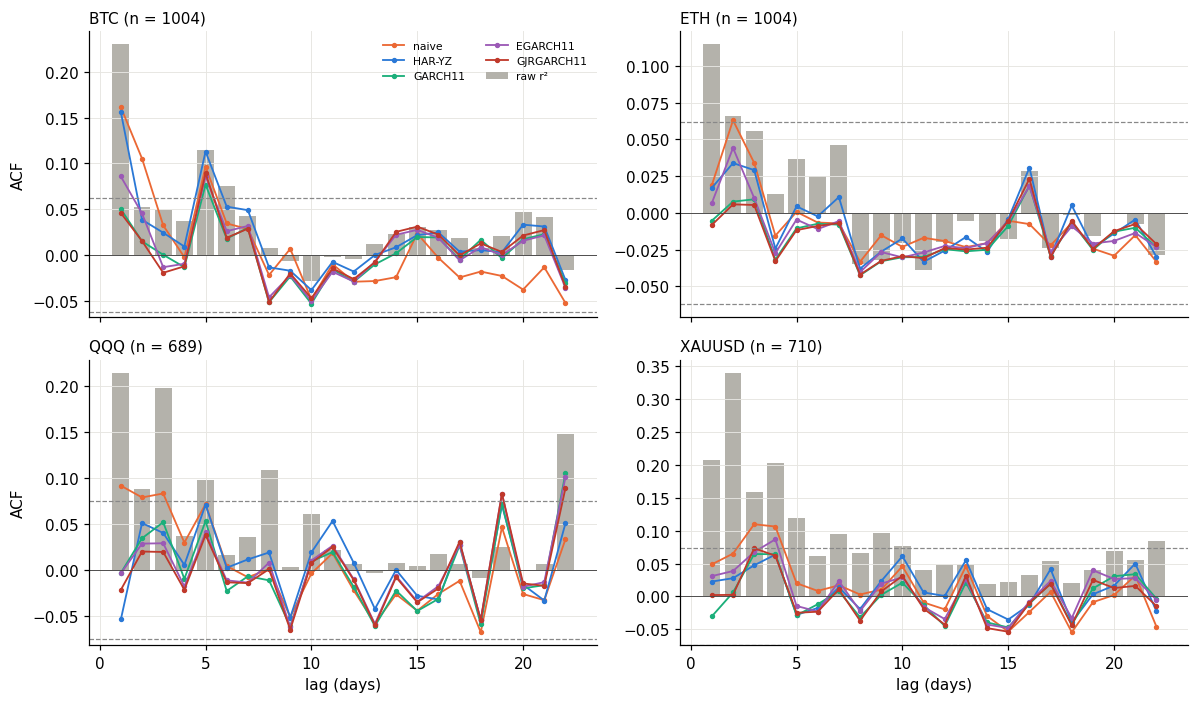

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
k = np.arange(1, 23)
for ax, s in zip(axes.flat, ASSETS):
    z, n = Z[s], len(Z[s])
    ax.bar(k, acf(data[s].y, nlags=22)[1:], color=COL['raw r²'], width=0.8, label='raw r²')
    for m in FORECASTS:
        ax.plot(k, acf(z[m]**2, nlags=22)[1:], marker='o', ms=2.5, color=COL[m], label=m)
    b = 1.96 / np.sqrt(n)
    ax.axhline(b, ls='--', color='#888', lw=0.8); ax.axhline(-b, ls='--', color='#888', lw=0.8)
    ax.axhline(0, color='#444', lw=0.6)
    ax.set_title(f'{s} (n = {n})', loc='left', fontsize=10)
for ax in axes[1]: ax.set_xlabel('lag (days)')
for ax in axes[:, 0]: ax.set_ylabel('ACF')
axes[0, 0].legend(frameon=False, fontsize=7, ncol=2)
fig.tight_layout()

## C. Empirical distribution

QQ plot of Z against the standard normal. Points above the line on the right / below on the left = heavier tails than normal. Normality is not required.

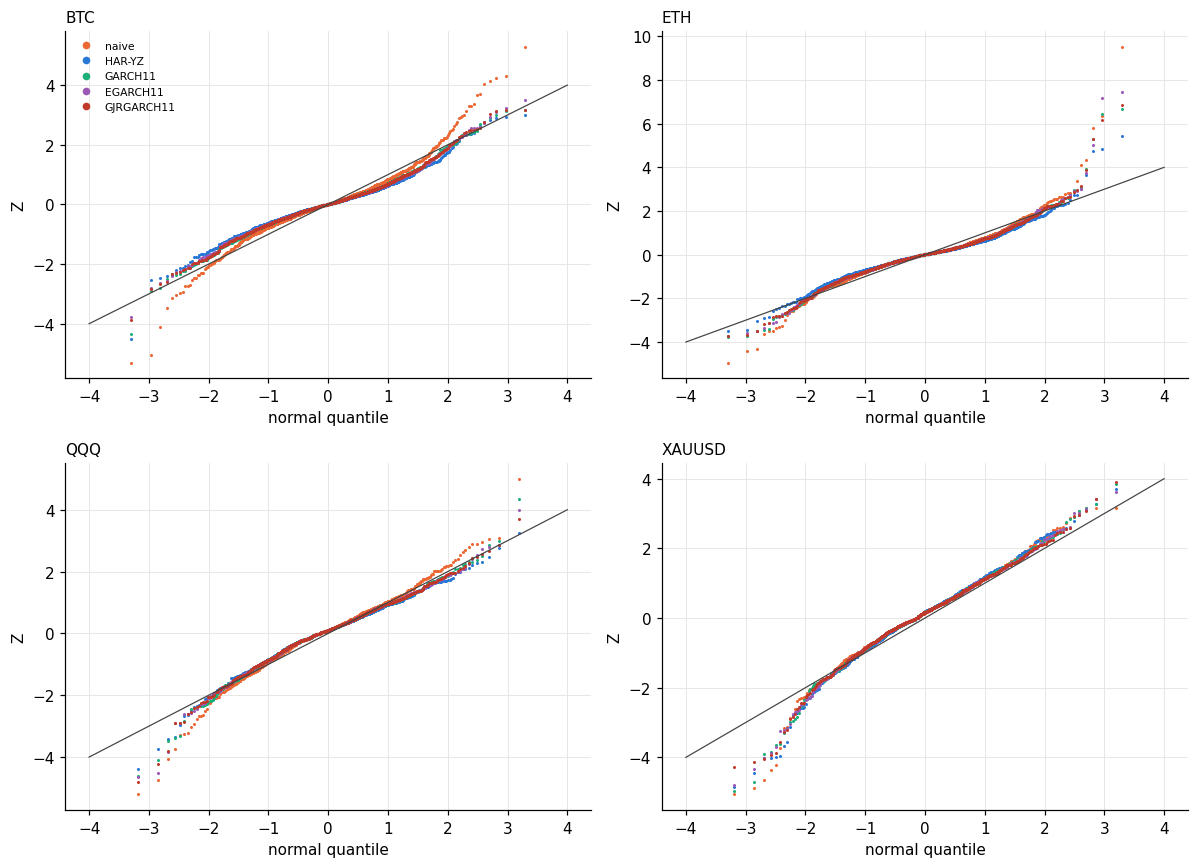

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, s in zip(axes.flat, ASSETS):
    for m in FORECASTS:
        z = np.sort(Z[s][m].to_numpy())
        q = stats.norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))
        ax.plot(q, z, '.', ms=2, color=COL[m], label=m)
    ax.plot([-4, 4], [-4, 4], color='#444', lw=0.8)
    ax.set_title(s, loc='left', fontsize=10); ax.set_xlabel('normal quantile'); ax.set_ylabel('Z')
axes[0, 0].legend(frameon=False, fontsize=7, markerscale=4)
fig.tight_layout()

## Findings (test 2024-01-01 → 2026-09-30; run 2026-11-01; provisional r² target)

**A. Calibration: the models get the variance level wrong in opposite directions for crypto and gold.**

| Asset | naive mean Z² | model mean Z² | Reading |
|---|---:|---:|---|
| BTC | 1.04 | 0.58–0.68 | Every model **overestimates** variance by about 1.5×, in every test year |
| ETH | 1.11 | 0.75 (HAR) / 0.91–0.94 (GARCH family) | HAR overestimates; GARCH family close |
| QQQ | 1.22 | 0.89–0.98 | Models well calibrated; naive underestimates |
| XAUUSD | 1.24 | 1.18–1.31 | Everything **underestimates**, worst in 2026 (1.5–1.7) |

- BTC: the fits carry the high-vol 2019–23 history into calmer 2024–26. QLIKE penalises overestimation less than underestimation, so a model can beat naive on QLIKE while being clearly mis-scaled.
- Gold: vol rose in 2025–26 and every forecast lagged behind it.

**B. Clustering: the GARCH family removes it; HAR-YZ and naive do not on BTC.**

- Raw r² is strongly clustered on every asset except ETH (Q22 p ≈ 0.06, weak to start with, so ETH can't tell models apart here).
- GARCH / EGARCH / GJR: no significant clustering left at lag 22 on any asset (Z² p22 ≥ 0.14; |Z| p22 ≥ 0.27).
- **BTC HAR-YZ: still clustered (Z² Q22 = 51 vs raw 89, p < 0.001; |Z| p22 = 0.03).** It leaves more than half the clustering, close to naive. This is the "near-flat HAR" problem showing up in the timing check.
- BTC EGARCH: lag-5 Z² p = 0.004, but |Z| is clean (p5 = 0.39), so it is driven by a few extreme days.
- QQQ: every model shows a Z² ACF spike near lag 22 (≈ 0.10) that is also in raw r². Possibly monthly macro releases; not investigated.

**C. Distribution.** Heavy tails everywhere (excess kurtosis 1.5–2.8 for models; ETH 4.6–7.8). Skew is negative for QQQ and gold (crash side), positive for crypto. Gold's left tail is the heaviest relative to normal (Z down to −5).
